# Ağ Trafiği Kümeleme (CICIDS2017) — CRISP-DM

**Problem:** Ağ akışlarını (network flow) benzerliklerine göre **etiket kullanmadan** kümelere ayırmak ve bu kümelerin
saldırı paternleriyle (DoS, DDoS, PortScan, Brute Force, Bot …) ne kadar örtüştüğünü incelemek.

**Veri seti:** [CICIDS2017](https://www.unb.ca/cic/datasets/ids-2017.html) — Canadian Institute for Cybersecurity, 2.8 milyon akış, 78 akış özelliği.
Referans çalışma: [Machine-Learning-Network-Security](https://github.com/Karan-D-Software/Machine-Learning-Network-Security).
Bu repoda 8 günlük CSV'nin tamamından **sınıf başına sınırlı (BENIGN 12.000, her saldırı türü en fazla 1.500) 27.720 satırlık** örnek kullanılır.

**Yöntem:** Ölçekleme + log dönüşümü → PCA ile boyut indirgeme → birden fazla algoritma (K-Means, MiniBatch K-Means,
Gaussian Mixture, Agglomerative, DBSCAN) → **AutoML**: Genetik Algoritma ile algoritma + hiperparametre + PCA boyutu seçimi.

## 1. İş Anlayışı (Business Understanding)
- İmza tabanlı IDS'ler yalnızca bilinen saldırıları yakalar. Kümeleme, etiket gerektirmeden **benzer davranışları gruplayarak** yeni/bilinmeyen paternleri ortaya çıkarabilir.
- Hedef: (1) iç tutarlılığı yüksek kümeler bulmak (**Silhouette**, **Davies-Bouldin**), (2) kümelerin gerçek trafik türleriyle örtüşmesini ölçmek
  (etiketler yalnızca **değerlendirme** için kullanılır: **Adjusted Rand Index**, **küme saflığı**).
- Zorluklar: 78 boyut, aşırı çarpık (right-skewed) dağılımlar, aykırı değerler ve gürültü.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans, MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, davies_bouldin_score, normalized_mutual_info_score,
                             silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 42
DATA = Path("../data")
FIG = Path("../docs/figures"); FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

## 2. Veri Anlayışı (Data Understanding)

In [2]:
df = pd.read_csv(DATA / "cicids2017_sample.csv")
print(df.shape)
df["Label"].value_counts()

(27720, 79)


Label
BENIGN                        12000
DDoS                           1500
FTP-Patator                    1500
DoS GoldenEye                  1500
DoS slowloris                  1500
SSH-Patator                    1500
DoS Hulk                       1500
DoS Slowhttptest               1500
Bot                            1500
Web Attack - Brute Force       1500
PortScan                       1500
Web Attack - XSS                652
Infiltration                     36
Web Attack - Sql Injection       21
Heartbleed                       11
Name: count, dtype: int64

In [3]:
df["Group"] = df["Label"].replace({
    "DoS Hulk": "DoS", "DoS GoldenEye": "DoS", "DoS slowloris": "DoS", "DoS Slowhttptest": "DoS", "Heartbleed": "DoS",
    "FTP-Patator": "Brute Force", "SSH-Patator": "Brute Force",
    "Web Attack - Brute Force": "Web Attack", "Web Attack - XSS": "Web Attack", "Web Attack - Sql Injection": "Web Attack",
})
features = df.drop(columns=["Label", "Group"])
const = features.columns[features.nunique() <= 1]
print("Sabit (varyansı 0) sütunlar çıkarılıyor:", list(const))
features = features.drop(columns=const)
print("Özellik sayısı:", features.shape[1])
features.describe().T[["mean", "50%", "max"]].head(12)

Sabit (varyansı 0) sütunlar çıkarılıyor: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Özellik sayısı: 70


,mean,50%,max
Destination Port,5.568050e+03,80.0,6.544500e+04
Flow Duration,1.772072e+07,179464.0,1.199952e+08
Total Fwd Packets,8.612807e+00,3.0,6.969000e+03
Total Backward Packets,7.661616e+00,2.0,9.269000e+03
Total Length of Fwd Packets,1.206767e+03,46.0,2.866110e+06
Total Length of Bwd Packets,7.679086e+03,18.0,2.000000e+07
Fwd Packet Length Max,1.948673e+02,24.0,2.336000e+04
Fwd Packet Length Min,1.731295e+01,0.0,1.983000e+03
Fwd Packet Length Mean,5.785972e+01,12.0,5.940857e+03
Fwd Packet Length Std,6.319235e+01,0.0,7.049469e+03


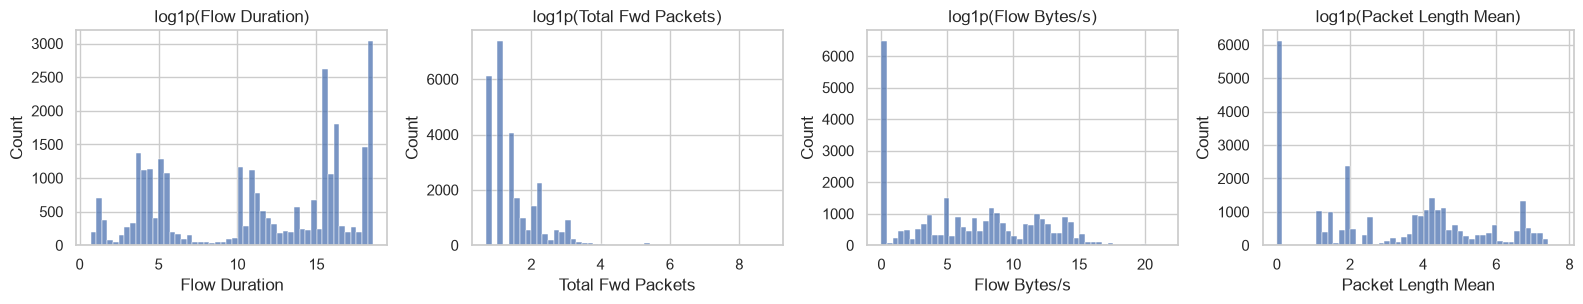

In [4]:
cols = ["Flow Duration", "Total Fwd Packets", "Flow Bytes/s", "Packet Length Mean"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, c in zip(axes, cols):
    sns.histplot(np.log1p(features[c].clip(lower=0)), bins=50, ax=ax); ax.set_title(f"log1p({c})")
plt.tight_layout(); plt.savefig(FIG / "skewed_features.png", dpi=120); plt.show()

**Gözlemler:** Özelliklerin büyük kısmı aşırı sağa çarpık (çok sayıda kısa akış, az sayıda çok uzun akış).
Bu nedenle mesafe tabanlı kümelemeden önce `log1p` dönüşümü ve standartlaştırma uygulanır. Ayrıca birbirine çok benzeyen
(korelasyonu > 0.95) özellikler gereksiz boyut yaratır.

## 3. Veri Hazırlama (Data Preparation)

Yüksek korelasyon nedeniyle 31 sütun çıkarıldı → 39 özellik kaldı


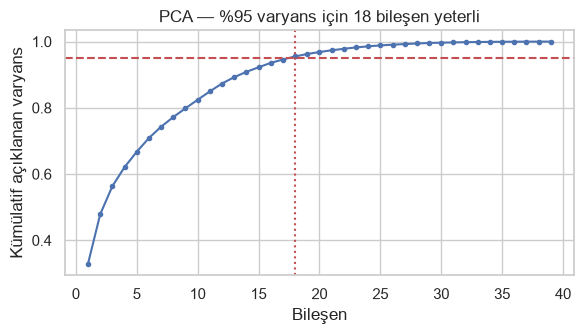

In [5]:
X = np.log1p(features.clip(lower=0))
corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
drop_corr = [c for c in upper.columns if (upper[c] > 0.95).any()]
X = X.drop(columns=drop_corr)
print(f"Yüksek korelasyon nedeniyle {len(drop_corr)} sütun çıkarıldı → {X.shape[1]} özellik kaldı")
X_scaled = StandardScaler().fit_transform(X)

pca_full = PCA(random_state=SEED).fit(X_scaled)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.searchsorted(cum, 0.95) + 1)
plt.figure(figsize=(6, 3.5)); plt.plot(range(1, len(cum) + 1), cum, marker=".")
plt.axhline(0.95, color="r", ls="--"); plt.axvline(n95, color="r", ls=":")
plt.title(f"PCA — %95 varyans için {n95} bileşen yeterli"); plt.xlabel("Bileşen"); plt.ylabel("Kümülatif açıklanan varyans")
plt.tight_layout(); plt.savefig(FIG / "pca_variance.png", dpi=120); plt.show()

## 4. Modelleme (Modeling)
### 4.1 Birden fazla algoritmanın karşılaştırılması (PCA %95 uzayında)
Silhouette hesaplaması O(n²) olduğu için tüm metrikler sabit tohumlu 8.000 satırlık bir alt örnek üzerinde hesaplanır.

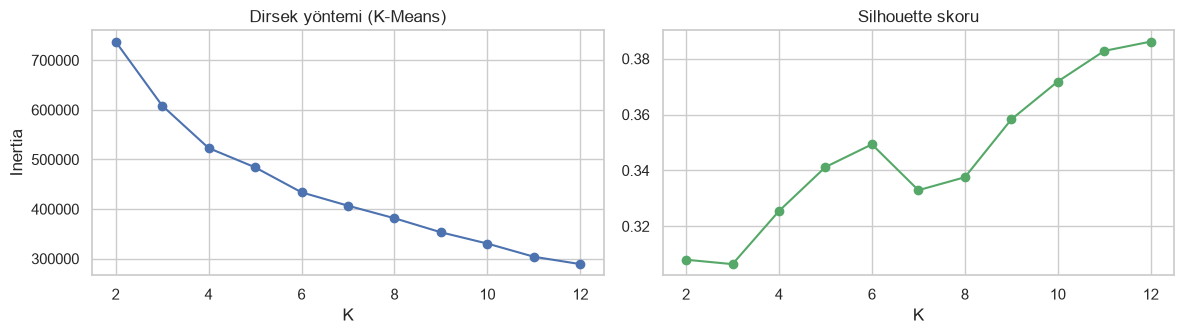

In [6]:
Z = PCA(n_components=n95, random_state=SEED).fit_transform(X_scaled)
y_true = df["Group"].values
rng = np.random.default_rng(SEED)
eval_idx = rng.choice(len(Z), size=8000, replace=False)


def evaluate(labels, name):
    lab = labels[eval_idx]
    mask = lab != -1                      # DBSCAN gürültü noktaları metrik dışı
    k = len(set(lab[mask]))
    if k < 2:
        return {"Model": name, "Küme": k}
    return {"Model": name, "Küme": k, "Gürültü %": round(100 * (1 - mask.mean()), 1),
            "Silhouette": silhouette_score(Z[eval_idx][mask], lab[mask], random_state=SEED),
            "Davies-Bouldin": davies_bouldin_score(Z[eval_idx][mask], lab[mask]),
            "ARI": adjusted_rand_score(y_true[eval_idx][mask], lab[mask]),
            "NMI": normalized_mutual_info_score(y_true[eval_idx][mask], lab[mask])}


# Dirsek yöntemi + silhouette ile K seçimi
ks, inertia, sil = range(2, 13), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    inertia.append(km.inertia_); sil.append(silhouette_score(Z[eval_idx], km.labels_[eval_idx]))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(ks, inertia, "o-"); ax[0].set(title="Dirsek yöntemi (K-Means)", xlabel="K", ylabel="Inertia")
ax[1].plot(ks, sil, "o-", color="g"); ax[1].set(title="Silhouette skoru", xlabel="K")
plt.tight_layout(); plt.savefig(FIG / "elbow_silhouette.png", dpi=120); plt.show()

In [7]:
K = 7   # gerçek trafik grubu sayısı (BENIGN, DoS, DDoS, PortScan, Brute Force, Web Attack, Bot+Infiltration) civarı
sub = rng.choice(len(Z), size=8000, replace=False)   # Agglomerative O(n²) bellek → alt örnek + en yakın merkez ataması
agg_sub = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Z[sub])
centers = np.vstack([Z[sub][agg_sub == c].mean(0) for c in range(K)])
agg_all = np.argmin(((Z[:, None, :] - centers[None]) ** 2).sum(-1), axis=1)

models = {
    "K-Means": KMeans(n_clusters=K, n_init=10, random_state=SEED).fit_predict(Z),
    "MiniBatch K-Means": MiniBatchKMeans(n_clusters=K, n_init=10, random_state=SEED, batch_size=2048).fit_predict(Z),
    "Gaussian Mixture": GaussianMixture(n_components=K, covariance_type="full", random_state=SEED).fit(Z).predict(Z),
    "Agglomerative (Ward)": agg_all,
    "DBSCAN": DBSCAN(eps=1.5, min_samples=20, n_jobs=-1).fit_predict(Z),
}
baseline = pd.DataFrame([evaluate(lab, name) for name, lab in models.items()]).round(4)
baseline

,Model,Küme,Gürültü %,Silhouette,Davies-Bouldin,ARI,NMI
0,K-Means,7,0.0,0.3329,1.4733,0.1972,0.3324
1,MiniBatch K-Means,7,0.0,0.3152,1.4760,0.2042,0.3483
2,Gaussian Mixture,7,0.0,0.2872,1.8298,0.1980,0.3581
3,Agglomerative (Ward),7,0.0,0.3606,1.2810,0.1484,0.2871
4,DBSCAN,70,4.8,0.5172,0.7404,0.1357,0.4997


### 4.2 AutoML — Genetik Algoritma ile algoritma + hiperparametre + boyut seçimi

Etiketsiz bir problemde AutoML'in amaç fonksiyonu da etiketsiz olmalıdır. Bu yüzden **Silhouette** skoru maksimize edilir;
tek kümeye çökmeyi ve aşırı gürültüyü engellemek için küme sayısı ≥ 3 ve gürültü ≤ %20 kısıtları cezalandırılır.
Arama uzayı: algoritma (K-Means / Gaussian Mixture / DBSCAN), PCA bileşen sayısı ve algoritmaya özel parametreler.
Gerçek etiketler (ARI) **sadece sonuçta** raporlanır, optimizasyona girmez.

In [8]:
pca_cache = {}


def get_Z(n):
    if n not in pca_cache:
        pca_cache[n] = PCA(n_components=n, random_state=SEED).fit_transform(X_scaled)
    return pca_cache[n]


def cluster(params):
    Zn = get_Z(params["n_components"])
    algo = params["algorithm"]
    if algo == "KMeans":
        return KMeans(n_clusters=params["k"], n_init=5, random_state=SEED).fit_predict(Zn), Zn
    if algo == "GaussianMixture":
        return GaussianMixture(n_components=params["k"], covariance_type=params["cov"], random_state=SEED).fit(Zn).predict(Zn), Zn
    return DBSCAN(eps=params["eps"], min_samples=params["min_samples"], n_jobs=-1).fit_predict(Zn), Zn


def objective(trial):
    p = {"algorithm": trial.suggest_categorical("algorithm", ["KMeans", "GaussianMixture", "DBSCAN"]),
         "n_components": trial.suggest_int("n_components", 3, n95)}
    if p["algorithm"] == "DBSCAN":
        p["eps"] = trial.suggest_float("eps", 0.3, 4.0)
        p["min_samples"] = trial.suggest_int("min_samples", 5, 60)
    else:
        p["k"] = trial.suggest_int("k", 3, 15)
        if p["algorithm"] == "GaussianMixture":
            p["cov"] = trial.suggest_categorical("cov", ["full", "diag"])
    labels, Zn = cluster(p)
    lab = labels[eval_idx]; mask = lab != -1
    k = len(set(lab[mask]))
    if k < 3 or mask.mean() < 0.8:
        return -1.0
    return silhouette_score(Zn[eval_idx][mask], lab[mask], random_state=SEED)


sampler = optuna.samplers.NSGAIISampler(population_size=12, mutation_prob=0.25, seed=SEED)
study = optuna.create_study(direction="maximize", sampler=sampler)
study.optimize(objective, n_trials=60)
print("En iyi Silhouette:", round(study.best_value, 4)); print("En iyi konfigürasyon:", study.best_params)

En iyi Silhouette: 0.6829
En iyi konfigürasyon: {'algorithm': 'DBSCAN', 'n_components': 5, 'eps': 0.5406908940455342, 'min_samples': 58}


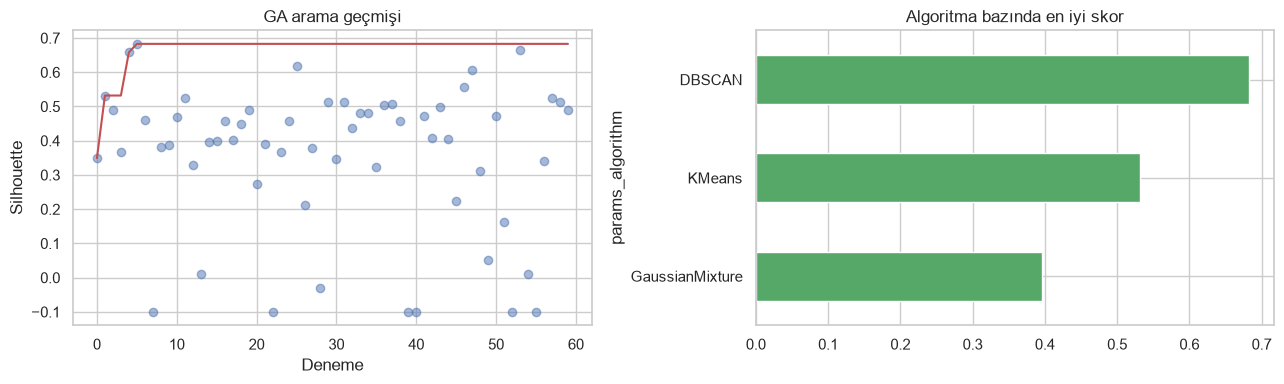

In [9]:
hist = study.trials_dataframe()[["number", "value", "params_algorithm"]]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(hist["number"], hist["value"].clip(lower=-0.1), "o", alpha=.5)
axes[0].plot(hist["number"], hist["value"].cummax(), "r-"); axes[0].set(title="GA arama geçmişi", xlabel="Deneme", ylabel="Silhouette")
hist.groupby("params_algorithm")["value"].max().sort_values().plot.barh(ax=axes[1], color="#55A868"); axes[1].set_title("Algoritma bazında en iyi skor")
plt.tight_layout(); plt.savefig(FIG / "automl_history.png", dpi=120); plt.show()

## 5. Değerlendirme (Evaluation)

In [10]:
best_labels, Z_best = cluster(study.best_params)
models[f"AutoML ({study.best_params['algorithm']})"] = best_labels
summary = pd.DataFrame([evaluate(lab, name) for name, lab in models.items()]).round(4)
summary

,Model,Küme,Gürültü %,Silhouette,Davies-Bouldin,ARI,NMI
0,K-Means,7,0.0,0.3329,1.4733,0.1972,0.3324
1,MiniBatch K-Means,7,0.0,0.3152,1.4760,0.2042,0.3483
2,Gaussian Mixture,7,0.0,0.2872,1.8298,0.1980,0.3581
3,Agglomerative (Ward),7,0.0,0.3606,1.2810,0.1484,0.2871
4,DBSCAN,70,4.8,0.5172,0.7404,0.1357,0.4997
5,AutoML (DBSCAN),45,13.5,0.6425,0.5818,0.2347,0.5824


In [11]:
# Kümelerin hangi trafik türlerinden oluştuğu (etiketler yalnızca yorum için)
ct = pd.crosstab(pd.Series(best_labels, name="Küme"), pd.Series(y_true, name="Trafik grubu"))
purity = (ct.max(axis=1) / ct.sum(axis=1)).rename("Saflık")
display_ct = ct.assign(Baskın=ct.idxmax(axis=1), Saflık=purity.round(3), Boyut=ct.sum(axis=1))
print("Ağırlıklı ortalama küme saflığı:", round((ct.max(axis=1).sum() / ct.values.sum()), 4))
display_ct.sort_values("Boyut", ascending=False)

Ağırlıklı ortalama küme saflığı: 0.8869


Trafik grubu,BENIGN,Bot,Brute Force,DDoS,DoS,Infiltration,PortScan,Web Attack,Baskın,Saflık,Boyut
Küme,,,,,,,,,,,
-1,3034,41,25,11,581,33,13,7,BENIGN,0.810,3745
10,3129,0,0,0,0,0,0,0,BENIGN,1.000,3129
21,63,0,0,0,2,0,0,1812,Web Attack,0.965,1877
0,767,0,3,647,352,1,0,22,BENIGN,0.428,1792
25,1439,0,0,0,0,0,0,0,BENIGN,1.000,1439
6,89,0,746,0,3,0,0,156,Brute Force,0.751,994
2,175,0,0,0,799,0,0,0,DoS,0.820,974
8,323,557,0,0,0,0,0,0,Bot,0.633,880
27,3,0,0,0,0,0,773,0,PortScan,0.996,776


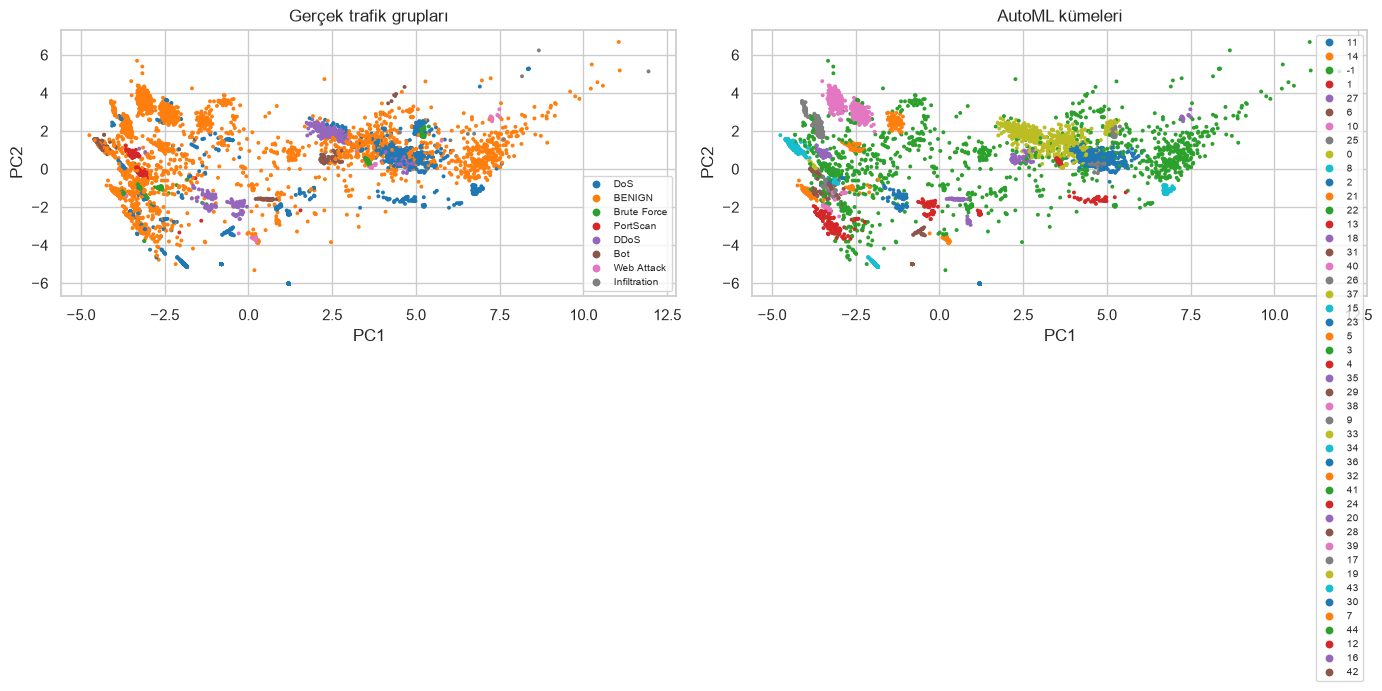

In [12]:
P2 = PCA(n_components=2, random_state=SEED).fit_transform(X_scaled)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, hue, title in [(axes[0], y_true, "Gerçek trafik grupları"), (axes[1], best_labels.astype(str), "AutoML kümeleri")]:
    sns.scatterplot(x=P2[eval_idx, 0], y=P2[eval_idx, 1], hue=np.asarray(hue)[eval_idx], s=8, linewidth=0, palette="tab10", ax=ax, legend="brief")
    ax.set(title=title, xlabel="PC1", ylabel="PC2"); ax.legend(markerscale=2, fontsize=7, loc="best")
plt.tight_layout(); plt.savefig(FIG / "clusters_pca.png", dpi=120); plt.show()

## 6. Dağıtım (Deployment) ve Sonuç
- **Kullanım senaryosu:** Kümeleme modeli SOC'ta "davranış profili" olarak kullanılabilir: yeni akış en yakın kümeye atanır; hiçbir kümeye
  yakın olmayan ya da küçük/saf saldırı kümelerine düşen akışlar analist incelemesine yönlendirilir.
- **Bulgular:** Yukarıdaki çapraz tabloda bazı kümeler neredeyse tamamen tek bir saldırı türünden oluşur (ör. PortScan, DDoS, DoS) — yani etiket kullanılmadan
  saldırı paternleri ayrışabilmektedir. BENIGN trafik ise birden çok kümeye dağılır (normal trafik heterojendir).
- **Silhouette ile ARI arasındaki gerilim:** İç tutarlılığı en yüksek çözüm, saldırı türlerini en iyi ayıran çözümle her zaman aynı değildir. Bu nedenle AutoML amacı
  (etiketsiz) ile iş amacı (saldırı keşfi) ayrı ayrı raporlandı.
- **Kısıtlar:** Sınıflar dengeli olacak şekilde örneklendi; gerçek trafikte saldırı oranı çok daha düşüktür. Infiltration/Heartbleed/SQLi çok az örnek içerir.